# CHIRPS v3 monthly precipitation

Inspect final monthly CHIRPS v3 precipitation for January 2020 near Nairobi. CHIRPS combines satellite-derived estimates and station observations into gridded monthly rainfall totals at approximately 0.05° resolution. Values represent precipitation over grid cells, in millimetres, not point observations or design-rainfall intensities. The gridded source is not a flood-depth or impact dataset. No daily disaggregation is used here.

The companion [pipeline](../../pipelines/chirps_monthly_pipeline.py) fetches and checksums the full monthly COG once, then reads only the requested pixel window. The source's `-9999` ocean/no-data sentinel is omitted; valid zero rainfall is retained. The requested bounds select a raster window and the coordinates are pixel centres. The result is not an area-weighted average. The snapshot cache and manifest permit offline replay; a source version label alone does not fix bytes.

Source: [Climate Hazards Center CHIRPS3 Data Repository](https://doi.org/10.15780/G2JQ0P), CC BY 4.0; [dataset description](https://www.chc.ucsb.edu/data/chirps3).

Run from a local crc-docs checkout: use `uv sync`, then launch Jupyter with
`uv run jupyter lab` and select the project kernel. The first pipeline run
requires internet access.


In [1]:
# Check the local notebook environment before running the pipeline.
import importlib.util
import subprocess
import sys
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
if IN_COLAB or importlib.util.find_spec("crc_sdk") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet",
                           "--disable-pip-version-check", "plotly>=6", "crc-sdk[raster]>=0.11.1,<1"])
root = next((folder for folder in (Path.cwd(), *Path.cwd().parents)
             if (folder / "pipelines").is_dir()), None)
if root is None:
    raise RuntimeError("Run this notebook from a crc-docs checkout (the pipelines folder is required).")
sys.path.insert(0, str(root))

import os

import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

STATIC_PREVIEW = os.environ.get("CRC_NOTEBOOK_STATIC_PREVIEW") == "1"
pio.renderers.default = "colab" if IN_COLAB else "plotly_mimetype+png" if STATIC_PREVIEW else "plotly_mimetype"
pio.templates.default = "plotly_white"
pio.defaults.default_width = 1000
pio.defaults.default_height = 470
from pipelines.chirps_monthly_pipeline import run
import pyarrow.parquet as pq

output = root / "pipeline_output" / "chirps_monthly"
result = run(output)
print("Valid grid cells:", result["valid_pixels"])
print("Snapshot SHA-256:", result["source"]["sha256"])
print("Retrieved:", result["source"]["retrieved_at"])

Valid grid cells: 9
Snapshot SHA-256: b0c7a1520e99d355253645a5f97688a9598f37ccba9370a4d4c9753df88d2458
Retrieved: 2026-10-30T19:10:52.043790+00:00


In [2]:
pixels = pq.read_table(output / "monthly.parquet").to_pandas()
pixels.sort_values(["latitude", "longitude"])

,longitude,latitude,precipitation_mm,month
6,36.725003,-1.325001,168.766174,2020-01-01
7,36.775003,-1.325001,181.057510,2020-01-01
8,36.825003,-1.325001,172.634293,2020-01-01
3,36.725003,-1.275001,162.263214,2020-01-01
4,36.775003,-1.275001,166.290787,2020-01-01
5,36.825003,-1.275001,148.933212,2020-01-01
0,36.725003,-1.225001,161.160782,2020-01-01
1,36.775003,-1.225001,148.450378,2020-01-01
2,36.825003,-1.225001,121.486069,2020-01-01


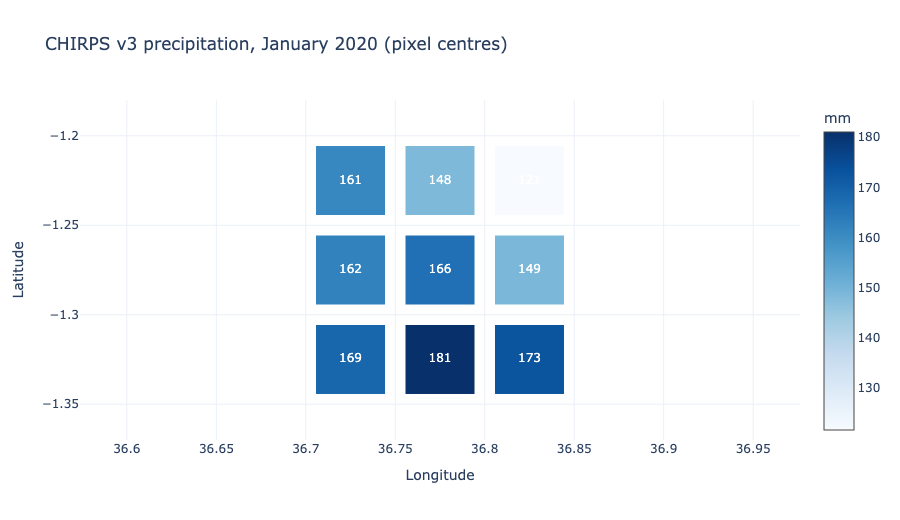

In [3]:
# Pixel centres coloured by monthly precipitation (mm).
fig = go.Figure(go.Scatter(
    x=pixels["longitude"], y=pixels["latitude"], mode="markers+text",
    text=pixels["precipitation_mm"].round(0).astype(int).astype(str),
    textfont=dict(color="white"),
    marker=dict(symbol="square", size=70, color=pixels["precipitation_mm"],
                colorscale="Blues", cmin=0, colorbar=dict(title="mm"), line=dict(width=1, color="white")),
))
fig.update_layout(title="CHIRPS v3 precipitation, January 2020 (pixel centres)",
                  xaxis_title="Longitude", yaxis_title="Latitude",
                  xaxis=dict(range=[36.68, 36.87]), yaxis=dict(range=[-1.37, -1.18], scaleanchor="x"),
                  height=520, width=900)
fig.show()


Pixel values vary across the selected window. A single month cannot establish an anomaly or long-term trend; those require an explicitly chosen comparable baseline, completeness rules and a spatial aggregation policy. Daily CHIRPS v3 products have separate reanalysis and satellite disaggregation methods and should not be interpreted as directly observed subdaily rainfall.